In [1]:
import cv2
print("OpenCV version:", cv2.__version__)
print("FLANN available:", hasattr(cv2, "FlannBasedMatcher"))

OpenCV version: 5.0.0
FLANN available: True


In [2]:
# ==========================================
# EXERCISE 1.2 - DATASET INITIALIZATION
# ==========================================

import numpy as np
import pandas as pd
import cv2
import time

from sklearn.datasets import fetch_openml
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

print("Loading MNIST dataset...")

mnist = fetch_openml(
    name="mnist_784",
    version=1,
    as_frame=False,
    parser="liac-arff"
)

X = mnist.data
y = mnist.target.astype(np.int64)

# Training dataset
X_train = X[:60000]
y_train = y[:60000]

# Testing dataset
X_test = X[60000:]
y_test = y[60000:]

# First 1000 testing samples
X_test_1000 = X_test[:1000]
y_test_1000 = y_test[:1000]

# Convert to float32 for FLANN
X_train_float = np.ascontiguousarray(
    X_train, dtype=np.float32
)

X_test_float = np.ascontiguousarray(
    X_test_1000, dtype=np.float32
)

print("\nMNIST initialized successfully!")

print("Training data:", X_train_float.shape)
print("Testing data:", X_test_float.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test_1000.shape)

Loading MNIST dataset...

MNIST initialized successfully!
Training data: (60000, 784)
Testing data: (1000, 784)
Training labels: (60000,)
Testing labels: (1000,)


In [3]:
FLANN_INDEX_KDTREE = 1

index_params = {
    "algorithm": FLANN_INDEX_KDTREE,
    "trees": 4
}

search_params = {
    "checks": 64
}

flann = cv2.FlannBasedMatcher(
    index_params,
    search_params
)

start = time.perf_counter()

flann.add([X_train_float])
flann.train()

index_build_time = time.perf_counter() - start

print("FLANN index built successfully!")
print("Index construction time:", index_build_time)

FLANN index built successfully!
Index construction time: 0.5232554169997456


In [4]:
# ==========================================
# STEP 4: APPROXIMATE NEAREST NEIGHBOUR SEARCH
# ==========================================

print("Performing FLANN approximate search...")

start = time.perf_counter()

flann_matches = flann.knnMatch(
    X_test_float,
    k=1
)

flann_query_time = time.perf_counter() - start

# Extract nearest training sample indices
nearest_indices = np.array([
    match[0].trainIdx
    for match in flann_matches
])

# Assign corresponding training labels
y_pred_flann = y_train[nearest_indices]

print("Approximate search completed!")

print("Prediction time:",
      round(flann_query_time, 4), "seconds")

print("Predictions:", y_pred_flann[:20])

Performing FLANN approximate search...
Approximate search completed!
Prediction time: 0.0504 seconds
Predictions: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]


In [5]:
# ==========================================
# STEP 5: FLANN CLASSIFICATION PERFORMANCE
# ==========================================

flann_accuracy = accuracy_score(
    y_test_1000,
    y_pred_flann
)

flann_error = (1 - flann_accuracy) * 100

correct = np.sum(y_pred_flann == y_test_1000)
incorrect = np.sum(y_pred_flann != y_test_1000)

print("\n========== FLANN RESULTS ==========")

print("Total test samples:", len(y_test_1000))
print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)

print("Accuracy:", round(flann_accuracy * 100, 2), "%")
print("Misclassification rate:", round(flann_error, 2), "%")


========== FLANN RESULTS ==========
Total test samples: 1000
Correct predictions: 950
Incorrect predictions: 50
Accuracy: 95.0 %
Misclassification rate: 5.0 %


In [6]:
# ==========================================
# STEP 6: EXACT KNN BASELINE
# ==========================================

exact_knn = KNeighborsClassifier(
    n_neighbors=1,
    metric="euclidean",
    algorithm="brute",
    n_jobs=-1
)

print("Training exact KNN...")

exact_knn.fit(X_train_float, y_train)

# Warm-up
exact_knn.predict(X_test_float[:10])

# Measure three prediction runs
exact_times = []

for i in range(3):

    start = time.perf_counter()

    y_pred_exact = exact_knn.predict(X_test_float)

    exact_times.append(time.perf_counter() - start)

exact_time = np.median(exact_times)

exact_accuracy = accuracy_score(
    y_test_1000,
    y_pred_exact
)

exact_error = (1 - exact_accuracy) * 100

print("\n========== EXACT KNN RESULTS ==========")

print("Prediction time:", round(exact_time, 4), "seconds")
print("Accuracy:", round(exact_accuracy * 100, 2), "%")
print("Error rate:", round(exact_error, 2), "%")

Training exact KNN...

========== EXACT KNN RESULTS ==========
Prediction time: 0.3179 seconds
Accuracy: 96.2 %
Error rate: 3.8 %


In [7]:
# ==========================================
# STEP 7: FINAL COMPARISON
# ==========================================

speedup = exact_time / flann_query_time

accuracy_drop = (
    exact_accuracy - flann_accuracy
) * 100

prediction_agreement = np.mean(
    y_pred_exact == y_pred_flann
) * 100

comparison = pd.DataFrame({
    "Metric": [
        "Prediction time (seconds)",
        "Accuracy (%)",
        "Error rate (%)"
    ],
    "Exact KNN": [
        exact_time,
        exact_accuracy * 100,
        exact_error
    ],
    "FLANN Approximate KNN": [
        flann_query_time,
        flann_accuracy * 100,
        flann_error
    ]
})

print("\n========== FINAL COMPARISON ==========")

print(comparison.to_string(index=False))

print("\nSpeedup:", round(speedup, 2), "x")

print("Accuracy drop:",
      round(accuracy_drop, 2), "percentage points")

print("Prediction agreement:",
      round(prediction_agreement, 2), "%")


========== FINAL COMPARISON ==========
                   Metric  Exact KNN  FLANN Approximate KNN
Prediction time (seconds)    0.31785               0.050391
             Accuracy (%)   96.20000              95.000000
           Error rate (%)    3.80000               5.000000

Speedup: 6.31 x
Accuracy drop: 1.2 percentage points
Prediction agreement: 97.3 %


In [8]:
# STEP 8: FLANN PARAMETER TUNING

check_values = [16, 32, 64, 128, 256]

tuning_results = []

for checks in check_values:

    print(f"\nTesting FLANN with checks={checks}")

    matcher = cv2.FlannBasedMatcher(
        {
            "algorithm": 1,
            "trees": 4
        },
        {
            "checks": checks
        }
    )

    # Build index
    start = time.perf_counter()

    matcher.add([X_train_float])
    matcher.train()

    build_time = time.perf_counter() - start

    # Approximate nearest-neighbour search
    start = time.perf_counter()

    matches = matcher.knnMatch(
        X_test_float,
        k=1
    )

    query_time = time.perf_counter() - start

    # Extract predicted labels
    indices = np.array([
        match[0].trainIdx
        for match in matches
    ])

    predictions = y_train[indices]

    # Evaluate accuracy
    acc = accuracy_score(
        y_test_1000,
        predictions
    ) * 100

    tuning_results.append({
        "Checks": checks,
        "Build Time (s)": build_time,
        "Query Time (s)": query_time,
        "Accuracy (%)": acc,
        "Error Rate (%)": 100 - acc
    })

print("\nParameter tuning completed!")


Testing FLANN with checks=16

Testing FLANN with checks=32

Testing FLANN with checks=64

Testing FLANN with checks=128

Testing FLANN with checks=256

Parameter tuning completed!


In [9]:
# STEP 9: DISPLAY TUNING RESULTS

tuning_df = pd.DataFrame(tuning_results)

print(tuning_df.to_string(index=False))

 Checks  Build Time (s)  Query Time (s)  Accuracy (%)  Error Rate (%)
     16        0.541026        0.009369          93.7             6.3
     32        0.470236        0.017158          94.0             6.0
     64        0.476151        0.030455          95.2             4.8
    128        0.472556        0.059044          95.6             4.4
    256        0.470615        0.120658          95.8             4.2


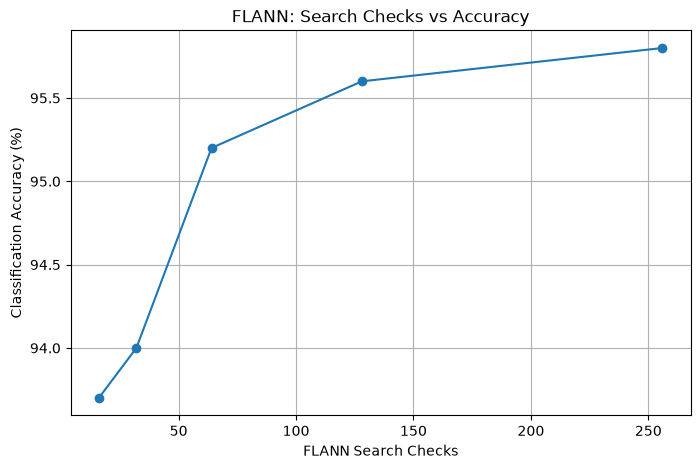

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    tuning_df["Checks"],
    tuning_df["Accuracy (%)"],
    marker="o"
)

plt.xlabel("FLANN Search Checks")
plt.ylabel("Classification Accuracy (%)")
plt.title("FLANN: Search Checks vs Accuracy")

plt.grid(True)
plt.show()

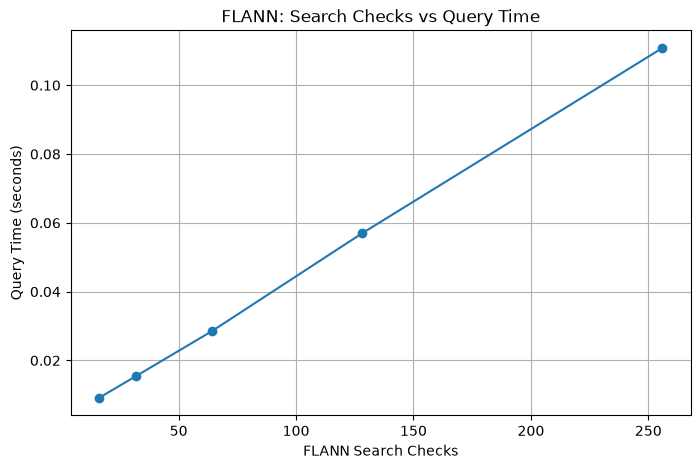

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    tuning_df["Checks"],
    tuning_df["Query Time (s)"],
    marker="o"
)

plt.xlabel("FLANN Search Checks")
plt.ylabel("Query Time (seconds)")
plt.title("FLANN: Search Checks vs Query Time")

plt.grid(True)
plt.show()

In [14]:
# STEP 10: END-TO-END PERFORMANCE

tuning_df["Total Time (s)"] = (
    tuning_df["Build Time (s)"] +
    tuning_df["Query Time (s)"]
)

tuning_df["End-to-End Speedup"] = (
    exact_time / tuning_df["Total Time (s)"]
)

print(tuning_df.to_string(index=False))

 Checks  Build Time (s)  Query Time (s)  Accuracy (%)  Error Rate (%)  Total Time (s)  End-to-End Speedup
     16        0.488752        0.009085          93.7             6.3        0.497836            0.600131
     32        0.452797        0.015512          94.0             6.0        0.468309            0.637969
     64        0.464993        0.028448          95.2             4.8        0.493441            0.605477
    128        0.457185        0.056908          95.6             4.4        0.514093            0.581153
    256        0.459141        0.110823          95.8             4.2        0.569964            0.524185
